# Capítulo 4 (continuación) — Condensados, costos, pozos de gas, estranguladores y raspatubos

Secciones 4.5 a 4.10. Las ecuaciones de flujo (4.1–4.4) están en `04_flujo_gas`.

> **Fuente.** Métodos y datos de *Transporte de Hidrocarburos por Ductos*, F. Garaicochea P.,
> C. Bernal H. y O. López O. (CIPM, 1991; reed. 2022), verificados contra la tesis UNAM de 1990 que
> le dio origen (Bernal y López, asesor Garaicochea). Los enunciados están **parafraseados**; consulte la
> obra original para el texto completo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ductos.pvt_gas import (Gas, peso_molecular_condensado, gamma_razasa_katz, gamma_vitter,
                            equivalente_gas_condensado, gasto_total_gas)
from ductos.gas import Gasoducto, p2_general
from ductos.costos_gas import (DatosCostosGas, razon_compresion_optima, diseno_economico,
                               barrido_presion_descarga, presion_descarga_optima, costo_total,
                               longitud_entre_estaciones)
from ductos.pozo_gas import (IPRGas, PozoGas, velocidad_erosion, gasto_erosion,
                             velocidad_turner, gasto_minimo_turner)
from ductos.estranguladores import (relacion_critica, relacion_temperatura_critica,
                                    relacion_densidad_critica, funcion_h, area_estrangulador,
                                    area_a_64avos, diametro_cook_dotterweich, gasto_estrangulador,
                                    dp_valvula_seguridad)
from ductos.raspatubos import velocidad_gas, velocidad_liquido

## 4.5 Presencia de condensados

Las ecuaciones de flujo suponen una sola fase. Cuando el gas arrastra condensado, una corrección aproximada es
usar la densidad relativa de la mezcla en lugar de la del gas (recomendable para RGL ≥ 10 000 pie³/bl; por debajo
conviene una correlación multifásica):

* **Razasa y Katz** (Ec. 4.52): $\gamma_{wg} = \dfrac{\gamma_g + 4584\,\gamma_o/R}{1 + 132\,800\,\gamma_o/(M_o R)}$, con $M_o = 6084/(°API-5.9)$ (Ec. 4.53).
* **Vitter** (Ec. 4.54), ponderando agua y condensado con la relación gas-líquido.
* **Ikoku** (Ecs. 4.55-4.56): equivalente en gas del condensado, $GE = 133\,037\,\gamma_o/M_o$, que se suma al gasto de gas.

**Ejercicio propuesto.** La línea del Ejemplo 4.2 transporta ahora gas de γ = 0.65 con 60 bl de condensado de 50 °API
por MMpie³ (RGC ≈ 16 700 pie³/bl). ¿Cuánto cambia la presión de llegada?

In [2]:
api, gg = 50, 0.65
go = 141.5 / (131.5 + api)
mo = peso_molecular_condensado(api=api)
rgc = 1e6 / 60
g_mezcla = gamma_razasa_katz(gg, go, rgc, mo)
ge = equivalente_gas_condensado(go, mo)
qg = 1100e6
qt = gasto_total_gas(qg, qg / rgc, ge)
print(f"γo = {go:.4f}, Mo = {mo:.1f}, γ mezcla (Razasa-Katz) = {g_mezcla:.4f}, γ (Vitter) = {gamma_vitter(gg, go, rgc):.4f}")
print(f"Equivalente en gas del condensado: {ge:.0f} pie³/bl  ->  gasto total {qt/1e6:.1f} MMpcd")
ducto = Gasoducto(28, 41, 150)
seco = p2_general(1900, qg, Gas(gg), ducto)["p2"]
humedo = p2_general(1900, qt, Gas(g_mezcla), ducto)["p2"]
print(f"p2 como gas seco: {seco:.0f} lb/pg²   con la corrección por condensado: {humedo:.0f} lb/pg²")

γo = 0.7796, Mo = 138.0, γ mezcla (Razasa-Katz) = 0.8272, γ (Vitter) = 0.8102
Equivalente en gas del condensado: 752 pie³/bl  ->  gasto total 1149.6 MMpcd
p2 como gas seco: 1560 lb/pg²   con la corrección por condensado: 1479 lb/pg²


## 4.6–4.7 Ecuación general de costos y diseño económico

El costo anual por milla tiene dos partes que se oponen al cambiar el diámetro (Fig. 4.5): la tubería
crece con $d^2$–$d^3$ y la compresión baja porque las estaciones pueden separarse más.

$$C_T = \underbrace{K_2\,P(p_d)\,(A d^2 + B d^3) + F_t}_{\text{tubería}} + \underbrace{K_3\,\frac{q\,a\,Z}{10^6 L}}_{\text{compresión}}$$

con $P(p) = p(2S'-p)/[4(S'-p)^2]$ (espesor por ASME B31, $S' = S F E T$), $a$ la potencia por MMpcd de Katz (Ec. 4.69) y
$L$ la distancia entre estaciones, ligada a $d$, $p_d$ y $p_e$ por la ecuación de flujo. El método de multiplicadores
de Lagrange (Huntington, modificado por Solórzano) minimiza $C_T$ sujeto a esa restricción.

### Ejemplo 4.7

**Planteamiento (parafraseado).** Encontrar $L$, $d$, $p_d$ y $p_e$ que minimizan el costo de transportar 1200 MMpcd de
gas de γ = 0.6. Los datos económicos y de compresión son los de la clase `DatosCostosGas`.

In [3]:
datos = DatosCostosGas()
rc = razon_compresion_optima(datos)
print(f"K1 = {datos.K1:.3f}  b = {datos.b:.5f}  fi = gr = {datos.fi:.4f}  K2 = {datos.K2:.3f}  K3 = {datos.K3:.2f}")
print(f"Razón de compresión óptima Rc = {rc:.4f}  ->  a = {datos.hp_por_mmpcd(rc):.2f} BHP/MMpcd")
print("Libro: K1 = 46.254, b = 0.21875, fi = 0.171, K2 = 4.823, K3 = 125.88, Rc = 1.1645, a = 9.46")

K1 = 46.254  b = 0.21875  fi = gr = 0.1710  K2 = 4.823  K3 = 125.94
Razón de compresión óptima Rc = 1.1645  ->  a = 9.46 BHP/MMpcd
Libro: K1 = 46.254, b = 0.21875, fi = 0.171, K2 = 4.823, K3 = 125.88, Rc = 1.1645, a = 9.46


La razón de compresión óptima no depende del diámetro: con $d$ fijo, $L \propto p_d^2(1-R_c^{-2})$ y el costo de
compresión por milla es proporcional a $a(R_c)/(1-R_c^{-2})$. Minimizar esa función reproduce el 1.1645 del libro.

**Paso a paso para $p_d$ = 1164.5 lb/pg² abs** (pasos 4 a 7 de la sección 4.7.4):

In [4]:
r = diseno_economico(1200e6, 1164.5, datos)
for k in ["pe", "Z", "dif", "d", "f", "K4", "L", "t", "tuberia", "compresion", "total"]:
    print(f"{k:11s} = {r[k]:,.5g}")
print("Libro: pe = 1000, Z = 0.854, dif = 0.01404, d = 35.32 pg, f = 0.0087679, K4 = 1777.6, L = 42.83 mi,")
print("       CT = 58 653.8 + 28 497.6 = 87 151.3 dll/año/milla")

pe          = 1,000
Z           = 0.8538
dif         = 0.014043
d           = 35.314
f           = 0.008768
K4          = 1,778.2
L           = 42.925
t           = 0.48914
tuberia     = 58,637
compresion  = 28,425
total       = 87,062
Libro: pe = 1000, Z = 0.854, dif = 0.01404, d = 35.32 pg, f = 0.0087679, K4 = 1777.6, L = 42.83 mi,
       CT = 58 653.8 + 28 497.6 = 87 151.3 dll/año/milla


### Tabla 4.8 y Fig. 4.8: costo total contra presión de descarga

In [5]:
libro_48 = pd.DataFrame({
    "pd": [4000, 3750, 3500, 3250, 3000, 2750, 2500, 2250, 2000, 1750, 1500, 1250, 1000, 750],
    "d libro": [21.14, 21.61, 22.15, 22.76, 23.47, 24.29, 25.26, 26.42, 27.81, 29.50, 31.59, 34.24, 37.72, 42.61],
    "L libro": [37.60, 37.72, 37.88, 38.08, 38.34, 38.66, 39.07, 39.58, 40.19, 40.89, 41.68, 42.53, 43.40, 44.25],
    "CT libro": [97272.69, 95113.11, 93115.43, 91306.11, 89719.34, 88396.06, 87370.90, 86673.50, 86313.33,
                 86269.38, 86489.88, 86901.29, 87426.79, 88008.42]})
calc = barrido_presion_descarga(1200e6, libro_48["pd"], datos)
libro_48["d"] = [c["d"] for c in calc]
libro_48["L"] = [c["L"] for c in calc]
libro_48["CT"] = [c["total"] for c in calc]
libro_48.round(2)

,pd,d libro,L libro,CT libro,d,L,CT
0,4000,21.14,37.60,97272.69,21.14,37.68,97253.91
1,3750,21.61,37.72,95113.11,21.61,37.81,95094.92
2,3500,22.15,37.88,93115.43,22.15,37.96,93096.64
3,3250,22.76,38.08,91306.11,22.76,38.16,91288.38
4,3000,23.47,38.34,89719.34,23.46,38.42,89704.28
5,2750,24.29,38.66,88396.06,24.29,38.75,88381.89
6,2500,25.26,39.07,87370.90,25.26,39.16,87358.28
7,2250,26.42,39.58,86673.50,26.42,39.67,86662.15
8,2000,27.81,40.19,86313.33,27.81,40.28,86302.74
9,1750,29.50,40.89,86269.38,29.50,40.99,86259.54


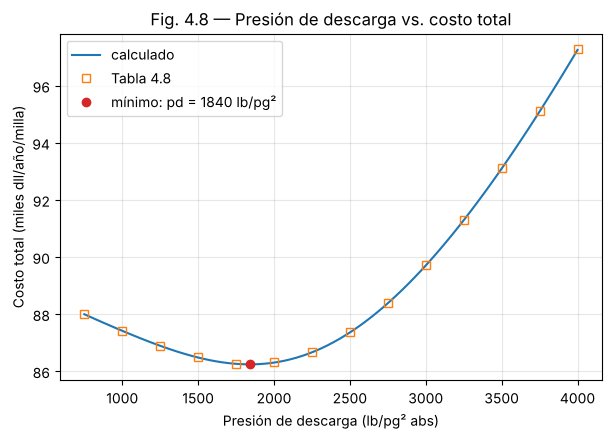

Óptimo continuo: pd = 1840, pe = 1580 lb/pg², d = 28.85 pg, L = 40.7 mi, espesor = 0.642 pg, CT = 86,241 dll/año/milla


In [6]:
opt = presion_descarga_optima(1200e6, datos)
pds = np.linspace(750, 4000, 80)
ct = [diseno_economico(1200e6, p, datos)["total"] for p in pds]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(pds, np.array(ct) / 1e3, label="calculado")
ax.plot(libro_48["pd"], libro_48["CT libro"] / 1e3, "s", mfc="none", label="Tabla 4.8")
ax.plot(opt["pd"], opt["total"] / 1e3, "o", c="C3", label=f"mínimo: pd = {opt['pd']:.0f} lb/pg²")
ax.set(xlabel="Presión de descarga (lb/pg² abs)", ylabel="Costo total (miles dll/año/milla)",
       title="Fig. 4.8 — Presión de descarga vs. costo total")
ax.grid(alpha=0.3); ax.legend(); plt.show()
print(f"Óptimo continuo: pd = {opt['pd']:.0f}, pe = {opt['pe']:.0f} lb/pg², d = {opt['d']:.2f} pg, "
      f"L = {opt['L']:.1f} mi, espesor = {opt['t']:.3f} pg, CT = {opt['total']:,.0f} dll/año/milla")

El libro elige 1750 lb/pg² porque es el mínimo de su malla de 250 en 250; la búsqueda continua da ≈1840 lb/pg², con una
diferencia de costo de apenas 0.03 %. La curva es muy plana alrededor del óptimo, así que la decisión final puede tomar
en cuenta otros criterios (clase de tubería, compresoras disponibles). El espesor calculado se redondea al comercial
inmediato superior.

### Compromiso tubería–compresión (Fig. 4.5)

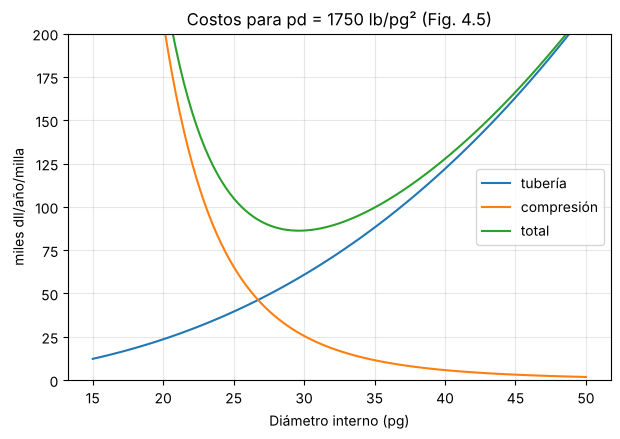

In [7]:
pd_, rc_ = 1750.0, rc
pe_ = pd_ / rc_
z_ = datos.gas.z(pe_, datos.t_flujo)
ds = np.linspace(15, 50, 120)
partes = [costo_total(1200e6, d, longitud_entre_estaciones(1200e6, d, pd_, pe_, z_, datos), pd_, rc_, z_, datos) for d in ds]
fig, ax = plt.subplots(figsize=(7, 4.5))
for clave, etiqueta in [("tuberia", "tubería"), ("compresion", "compresión"), ("total", "total")]:
    ax.plot(ds, [p[clave] / 1e3 for p in partes], label=etiqueta)
ax.set(xlabel="Diámetro interno (pg)", ylabel="miles dll/año/milla", ylim=(0, 200),
       title=f"Costos para pd = {pd_:.0f} lb/pg² (Fig. 4.5)")
ax.grid(alpha=0.3); ax.legend(); plt.show()

## 4.8 Predicción del comportamiento de un pozo productor de gas

Nodo de solución en la cabeza del pozo: desde el yacimiento se obtiene $p_{th}$ antes del estrangulador y desde el
separador la $p_e$ necesaria después de él. Donde las curvas se cruzan se tiene el gasto máximo sin estrangulador (Fig. 4.10).

### Ejemplo 4.8

**Datos.** Gas seco γ = 0.7; separador a 50 lb/pg² abs; TP de 2.441 pg y 1.1976 millas (6323 pies) a 140 °F;
línea de descarga de 2.991 pg y 1.865 millas a 60 °F con 300 pies de desnivel; ε = 0.0007 pg;
yacimiento $q = 16\,290\,(p_{ws}^2-p_{wf}^2)^{0.681}$.

> En la tesis escaneada no queda claro a qué elemento corresponden los 300 pies. Con 300 pies de subida en la línea
> de descarga se reproducen las presiones legibles de la tabla del libro (292, 698, 828 y 1081 lb/pg²).

In [8]:
pozo = PozoGas(gas=Gas(0.7), ipr=IPRGas(16290, 0.681),
               tp=Gasoducto(2.441, 1.1976, 140, h=1.1976 * 5280, rug=0.0007),
               ld=Gasoducto(2.991, 1.865, 60, h=300, rug=0.0007), p_sep=50)
qs = [2e6, 4e6, 8e6, 10e6, 12e6, 16e6]
filas = []
for q in qs:
    fila = {"q (MMpcd)": q / 1e6, "pe línea de descarga": pozo.pe(q)}
    for pws in (2000, 1500, 1000):
        fila[f"pth, pws={pws}"] = pozo.nodos(q, pws)["pth"] if q < pozo.ipr.q_max(pws) else np.nan
    filas.append(fila)
pd.DataFrame(filas).round(0)

,q (MMpcd),pe línea de descarga,"pth, pws=2000","pth, pws=1500","pth, pws=1000"
0,2.0,153.0,1675.0,1258.0,834.0
1,4.0,291.0,1647.0,1218.0,769.0
2,8.0,564.0,1528.0,1044.0,403.0
3,10.0,697.0,1432.0,888.0,NaN
4,12.0,827.0,1305.0,642.0,NaN
5,16.0,1078.0,893.0,NaN,NaN


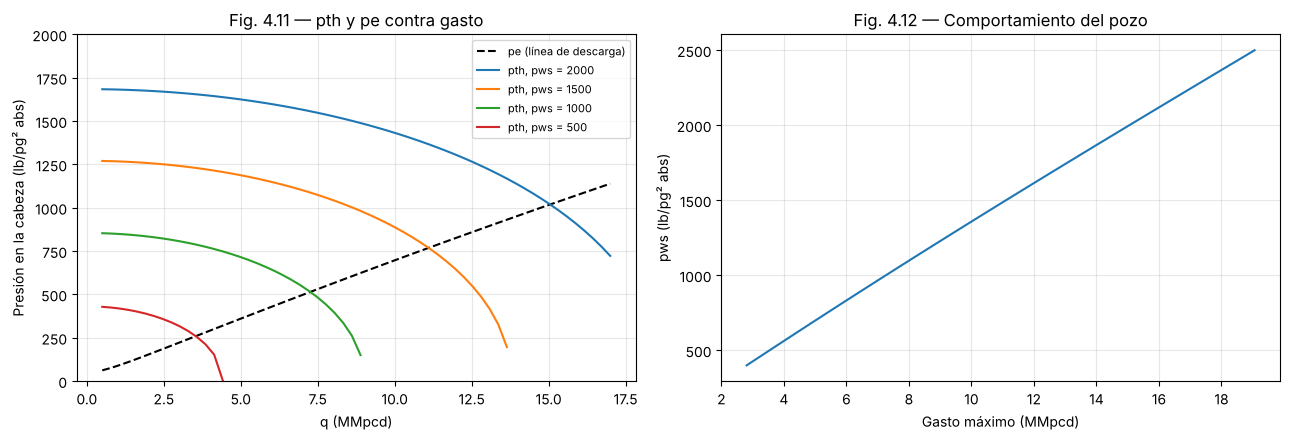

{2000: 15.05, 1500: 11.1, 1000: 7.26, 500: 3.54}


In [9]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
qq = np.linspace(0.5e6, 17e6, 60)
axs[0].plot(qq / 1e6, [pozo.pe(q) for q in qq], "k--", label="pe (línea de descarga)")
maximos = {}
for pws in (2000, 1500, 1000, 500):
    pth = []
    for q in qq:
        try:
            pth.append(pozo.pth(q, pws))
        except ValueError:
            pth.append(np.nan)
    axs[0].plot(qq / 1e6, pth, label=f"pth, pws = {pws}")
    maximos[pws] = pozo.gasto_maximo(pws)
axs[0].set(xlabel="q (MMpcd)", ylabel="Presión en la cabeza (lb/pg² abs)", ylim=(0, 2000),
           title="Fig. 4.11 — pth y pe contra gasto")
axs[0].legend(fontsize=8)
pws_v = np.linspace(400, 2500, 30)
axs[1].plot([pozo.gasto_maximo(p) / 1e6 for p in pws_v], pws_v)
axs[1].set(xlabel="Gasto máximo (MMpcd)", ylabel="pws (lb/pg² abs)", title="Fig. 4.12 — Comportamiento del pozo")
for a in axs: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print({p: round(q / 1e6, 2) for p, q in maximos.items()})

### 4.8.1–4.8.2 Ventana operativa: erosión y descarga de líquidos

El gasto debe quedar **debajo** del de erosión (Ec. 4.106, $v_e = c_4/\sqrt{\rho_g}$ con $c_4 \approx 100$) y **arriba** del mínimo
de Turner para que el gas arrastre las gotas de líquido (Ecs. 4.108-4.109). Se evalúan en la cabeza del pozo, donde la
presión es menor y la velocidad mayor.

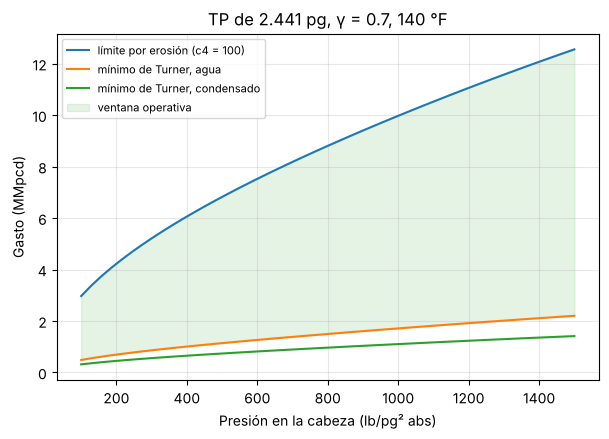

A 1000 lb/pg²: ve = 52.6 pie/s, v Turner (agua) = 9.0 pie/s


In [10]:
pth_v = np.linspace(100, 1500, 50)
g7 = Gas(0.7)
q_eros = [gasto_erosion(2.441, p, 140, g7) / 1e6 for p in pth_v]
q_agua = [gasto_minimo_turner(2.441, p, 140, g7, "agua") / 1e6 for p in pth_v]
q_cond = [gasto_minimo_turner(2.441, p, 140, g7, "condensado") / 1e6 for p in pth_v]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(pth_v, q_eros, label="límite por erosión (c4 = 100)")
ax.plot(pth_v, q_agua, label="mínimo de Turner, agua")
ax.plot(pth_v, q_cond, label="mínimo de Turner, condensado")
ax.fill_between(pth_v, q_agua, q_eros, alpha=0.12, color="C2", label="ventana operativa")
ax.set(xlabel="Presión en la cabeza (lb/pg² abs)", ylabel="Gasto (MMpcd)", title="TP de 2.441 pg, γ = 0.7, 140 °F")
ax.grid(alpha=0.3); ax.legend(fontsize=8); plt.show()
print(f"A 1000 lb/pg²: ve = {velocidad_erosion(1000, 140, g7):.1f} pie/s, v Turner (agua) = {velocidad_turner(1000):.1f} pie/s")

Con $p_{ws}$ = 2000 lb/pg² el gasto máximo sin estrangulador (≈15 MMpcd, con $p_{th}$ ≈ 1020 lb/pg²) **excede** el límite por
erosión de esta TP (≈10 MMpcd a esa presión): el pozo debe estrangularse aunque el yacimiento pueda dar más.

Si el gasto cae debajo del mínimo de Turner, el líquido se acumula en el fondo y el pozo puede "ahogarse". El libro
lista los remedios: bombeo mecánico, émbolo viajero, bombeo neumático, inyección de espumas o una tubería de menor
diámetro (sarta de velocidad).

## 4.9 Flujo de gas a través de estranguladores

### Relaciones críticas (Tabla 4.9)

In [11]:
pd.DataFrame({"k": [1.2, 1.3, 1.4, 1.67],
              "p*/p0": [relacion_critica(k) for k in (1.2, 1.3, 1.4, 1.67)],
              "T*/T0": [relacion_temperatura_critica(k) for k in (1.2, 1.3, 1.4, 1.67)],
              "ρ*/ρ0": [relacion_densidad_critica(k) for k in (1.2, 1.3, 1.4, 1.67)]}).round(4)

,k,p*/p0,T*/T0,ρ*/ρ0
0,1.20,0.5645,0.9091,0.6209
1,1.30,0.5457,0.8696,0.6276
2,1.40,0.5283,0.8333,0.6339
3,1.67,0.4867,0.7491,0.6497


### Ejemplo 4.9: diámetro de estrangulador

**Datos.** 1 340 927 pie³/día de gas γ = 0.69, k = 1.25 (medido), 140 °F, $p_{th}$ = 514.3 y $p_e$ = 411.5 lb/pg² abs, Z = 0.93.
Como $p_e/p_{th} = 0.8 > p^*/p_0 = 0.555$, el flujo es **subcrítico**.

In [12]:
g69 = Gas(0.69)
print(f"p*/p0 = {relacion_critica(1.25):.3f}   H = {funcion_h(0.8, 1.25):.4f}   [libro: 0.555, 0.0305]")
a = area_estrangulador(1340927, 514.3, 411.5, g69, 140, 1.25, cd=1.0, z=0.93)
print(f"Ec. 4.129 (Cd = 1): A = {a:.4f} pg², d = {area_a_64avos(a):.2f}/64 pg   [libro: 23.83/64 -> 24/64]")
cdt = diametro_cook_dotterweich(1340927, 514.3, 411.5, g69, 140, 1.25)
print(f"Cook-Dotterweich (Cd = {cdt['Cd']:.3f}): d = {cdt['d64']:.2f}/64 pg")

p*/p0 = 0.555   H = 0.0305   [libro: 0.555, 0.0305]
Ec. 4.129 (Cd = 1): A = 0.1053 pg², d = 23.43/64 pg   [libro: 23.83/64 -> 24/64]
Cook-Dotterweich (Cd = 0.829): d = 26.17/64 pg


Cook y Dotterweich introducen un coeficiente de descarga menor que uno (Ec. 4.132), así que piden un estrangulador
mayor (26/64 contra 24/64). La constante numérica de la Ec. 4.129 se dedujo aquí de primeros principios; el valor que
aparece en la tesis escaneada no es coherente con el resultado del ejemplo (ver `docs/erratas.md`).

### Curva del estrangulador: gasto contra $p_e/p_{th}$

Debajo de la relación crítica el gasto ya no depende de la presión corriente abajo: esa es la razón de diseñar los
estranguladores de cabeza en flujo crítico.

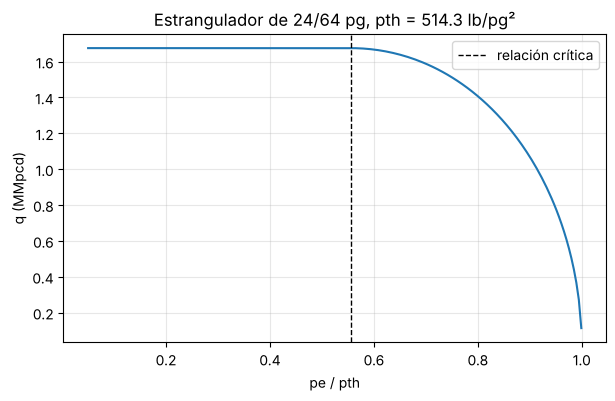

In [13]:
rs = np.linspace(0.05, 0.999, 200)
area_24 = np.pi / 4 * (24 / 64)**2
qs = [gasto_estrangulador(area_24, 514.3, r * 514.3, g69, 140, 1.25, z=0.93) / 1e6 for r in rs]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(rs, qs)
ax.axvline(relacion_critica(1.25), ls="--", c="k", lw=1, label="relación crítica")
ax.set(xlabel="pe / pth", ylabel="q (MMpcd)", title="Estrangulador de 24/64 pg, pth = 514.3 lb/pg²")
ax.grid(alpha=0.3); ax.legend(); plt.show()

La correlación de $k$ en función de γ y T (Ecs. 4.116-4.128) no se implementó porque sus coeficientes no son legibles
en la tesis escaneada; el ejemplo usa un valor medido.

### 4.9.4 Ejemplo 4.11: válvula de seguridad subsuperficial

Caída de presión en una válvula de 1.0 pg dentro de TP de 2.992 pg, con 55 MMpcd de gas γ = 0.6 a 1900 lb/pg² abs y 150 °F,
en flujo subcrítico, con el factor de expansión Y = 0.85 que propone el API.

In [14]:
for cd, z in [(0.895, 0.87), (0.9, None)]:
    r = dp_valvula_seguridad(55e6, 1900, 150, Gas(0.6), 2.992, 1.0, cd=cd, z=z)
    print(f"Cd = {cd}, Z = {r['Z']:.4f}: β = {r['beta']:.3f}, Δp = {r['dp']:.1f} lb/pg²")
print("Libro: β = 0.334, Δp = 907.74 lb/pg²")

Cd = 0.895, Z = 0.8700: β = 0.334, Δp = 908.7 lb/pg²
Cd = 0.9, Z = 0.8713: β = 0.334, Δp = 898.6 lb/pg²
Libro: β = 0.334, Δp = 907.74 lb/pg²


## 4.10 Raspatubos ("diablos")

Se usan para limpiar líneas, separar productos en poliductos, llenar o vaciar líneas y para pruebas hidrostáticas. Las
velocidades recomendadas son de 5 a 15 mph en gas y de 2 a 10 mph en líquidos.

**Ejemplos 4.12 y 4.13.** Línea de 19.25 pg con 200 000 bl/día de líquido, y la misma línea con 200 MMpcd de gas γ = 0.6
a 60 °F entre 1100 y 900 lb/pg² man.

In [15]:
rl = velocidad_liquido(200000, 19.25)
rg = velocidad_gas(200e6, 1100 + 15, 900 + 15, 60, 19.25, Gas(0.6))
print(f"Líquido: v = {rl['v']:.3f} pie/s ({rl['mph']:.1f} mph)  en rango: {rl['en_rango']}   [libro: 6.433 pie/s]")
print(f"Gas:     v = {rg['v']:.2f} pie/s ({rg['mph']:.1f} mph), Z = {rg['Z']:.4f}  en rango: {rg['en_rango']}   [libro: 13.93 pie/s, Z = 0.8402]")

Líquido: v = 6.433 pie/s (4.4 mph)  en rango: True   [libro: 6.433 pie/s]
Gas:     v = 13.94 pie/s (9.5 mph), Z = 0.8407  en rango: True   [libro: 13.93 pie/s, Z = 0.8402]
